# Rank Divergence Predicts Relative Control Energy

This notebook collects the results for the section testing whether disagreement between degree-based and topology-based rankings predicts relative scalar control energy.

It is designed to:
- summarize the subject-level rank-divergence result by parcellation scale,
- verify the exact test statistics used in the manuscript,
- inspect the distribution of relative energy differences,
- generate the figure for this section in a scale-resolved form.

In [71]:
from pathlib import Path
import os
import sys

os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib')

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr, wilcoxon

REPO_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

RESULTS_DIR = REPO_ROOT / 'results'
FIGURES_DIR = REPO_ROOT / 'figures' / 'section_rank_divergence_energy'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({'svg.fonttype': 'none', 'axes.unicode_minus': False})
sns.set_theme(context='talk', style='whitegrid')

In [72]:
rank_divergence = pd.read_csv(RESULTS_DIR / 'primary' / 'rank_divergence.csv')
node_level_energy = pd.read_csv(RESULTS_DIR / 'primary' / 'node_level_energy.csv')
scales = [68, 114, 219]
rank_divergence.head()

,subject_id,scale,spearman_degree_vs_topology,mean_delta_log10_energy,spectral_radius_before_shift
0,sub-000,68,0.677503,-0.001943,1.697112
1,sub-001,68,0.421885,0.000216,1.669784
2,sub-002,68,0.438475,-0.003734,1.233000
3,sub-003,68,0.505235,-0.001507,1.368192
4,sub-004,68,0.731705,-0.000854,1.900710


## Helpers

In [73]:
def holm_correction(p_values: list[float]) -> list[float]:
    p = np.asarray(p_values, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adjusted = np.empty(m, dtype=float)
    running = 0.0
    for rank, idx in enumerate(order):
        candidate = (m - rank) * p[idx]
        running = max(running, candidate)
        adjusted[idx] = min(running, 1.0)
    return adjusted.tolist()


def sem(values: pd.Series) -> float:
    values = pd.Series(values, dtype=float).dropna()
    if len(values) <= 1:
        return float('nan')
    return float(values.std(ddof=1) / np.sqrt(len(values)))

## Subject-level summaries

In [74]:
summary_rows = []
for scale in scales:
    subset = rank_divergence[rank_divergence['scale'] == scale].copy()
    rho, p_value = spearmanr(subset['spearman_degree_vs_topology'], subset['mean_delta_log10_energy'])
    summary_rows.append({
        'scale': scale,
        'n_subjects': len(subset),
        'mean_rank_alignment': subset['spearman_degree_vs_topology'].mean(),
        'sem_rank_alignment': sem(subset['spearman_degree_vs_topology']),
        'mean_delta_log10_energy': subset['mean_delta_log10_energy'].mean(),
        'sem_delta_log10_energy': sem(subset['mean_delta_log10_energy']),
        'rho_rank_vs_deltaE': rho,
        'p_rank_vs_deltaE': p_value,
    })
section_summary = pd.DataFrame(summary_rows)
section_summary

,scale,n_subjects,mean_rank_alignment,sem_rank_alignment,mean_delta_log10_energy,sem_delta_log10_energy,rho_rank_vs_deltaE,p_rank_vs_deltaE
0,68,70,0.480505,0.014402,-0.000576,0.000359,-0.431581,0.000191
1,114,70,0.386257,0.014625,0.000969,0.000224,-0.293395,0.013700
2,219,70,0.395427,0.010570,0.001097,0.000135,-0.252594,0.034889


In [75]:
section_summary_display = section_summary.copy()
for column in ['mean_rank_alignment', 'sem_rank_alignment', 'mean_delta_log10_energy', 'sem_delta_log10_energy', 'rho_rank_vs_deltaE']:
    section_summary_display[column] = section_summary_display[column].map(lambda x: f'{x:.6f}')
section_summary_display['p_rank_vs_deltaE'] = section_summary_display['p_rank_vs_deltaE'].map(lambda x: f'{x:.3e}')
section_summary_display

,scale,n_subjects,mean_rank_alignment,sem_rank_alignment,mean_delta_log10_energy,sem_delta_log10_energy,rho_rank_vs_deltaE,p_rank_vs_deltaE
0,68,70,0.480505,0.014402,-0.000576,0.000359,-0.431581,1.913e-04
1,114,70,0.386257,0.014625,0.000969,0.000224,-0.293395,1.370e-02
2,219,70,0.395427,0.010570,0.001097,0.000135,-0.252594,3.489e-02


## Exact correlation test and Holm correction

In [76]:
corr_rows = []
for scale in scales:
    subset = rank_divergence[rank_divergence['scale'] == scale].copy()
    rho, p_value = spearmanr(subset['spearman_degree_vs_topology'], subset['mean_delta_log10_energy'])
    corr_rows.append({
        'family': 'rank_divergence_vs_relative_energy',
        'scale': scale,
        'statistic': rho,
        'p_value': p_value,
        'n_subjects': subset.shape[0],
    })
correlation_tests = pd.DataFrame(corr_rows)
correlation_tests

,family,scale,statistic,p_value,n_subjects
0,rank_divergence_vs_relative_energy,68,-0.431581,0.000191,70
1,rank_divergence_vs_relative_energy,114,-0.293395,0.013700,70
2,rank_divergence_vs_relative_energy,219,-0.252594,0.034889,70


## Static cycle-versus-degree energy difference by scale

In [77]:
static_primary = node_level_energy[
    (node_level_energy['selection_strategy'] == 'static')
    & (node_level_energy['method'].isin(['degree_strength', 'cycle_participation']))
    & (node_level_energy['k'].isin([1, 2, 3, 5]))
].copy()

subject_mean = (
    static_primary.groupby(['subject_id', 'scale', 'method'], as_index=False)['log10_average_energy']
    .mean()
    .pivot(index=['subject_id', 'scale'], columns='method', values='log10_average_energy')
    .reset_index()
)
subject_mean['cycle_minus_degree'] = subject_mean['cycle_participation'] - subject_mean['degree_strength']

subject_by_k = (
    static_primary.groupby(['subject_id', 'scale', 'k', 'method'], as_index=False)['log10_average_energy']
    .mean()
    .pivot(index=['subject_id', 'scale', 'k'], columns='method', values='log10_average_energy')
    .reset_index()
)
subject_by_k['cycle_minus_degree'] = subject_by_k['cycle_participation'] - subject_by_k['degree_strength']
subject_mean.head()

method,subject_id,scale,cycle_participation,degree_strength,cycle_minus_degree
0,sub-000,68,6.759813,6.761756,-0.001943
1,sub-000,114,7.016582,7.015136,0.001446
2,sub-000,219,7.317744,7.317007,0.000737
3,sub-001,68,6.768380,6.768164,0.000216
4,sub-001,114,7.021322,7.020981,0.000341


In [78]:
energy_rows = []
for scale in scales:
    subset = subject_mean[subject_mean['scale'] == scale].copy()
    statistic, p_value = wilcoxon(subset['cycle_minus_degree'])
    energy_rows.append({
        'scale': scale,
        'n_subjects': len(subset),
        'mean_cycle_minus_degree': subset['cycle_minus_degree'].mean(),
        'sem_cycle_minus_degree': sem(subset['cycle_minus_degree']),
        'mean_cycle_energy': subset['cycle_participation'].mean(),
        'mean_degree_energy': subset['degree_strength'].mean(),
        'wilcoxon_statistic': statistic,
        'wilcoxon_p': p_value,
    })
energy_summary = pd.DataFrame(energy_rows)
energy_summary

,scale,n_subjects,mean_cycle_minus_degree,sem_cycle_minus_degree,mean_cycle_energy,mean_degree_energy,wilcoxon_statistic,wilcoxon_p
0,68,70,-0.000576,0.000359,6.767585,6.768161,880.0,3.388679e-02
1,114,70,0.000969,0.000224,7.019389,7.018419,611.0,2.193221e-04
2,219,70,0.001097,0.000135,7.320842,7.319745,82.0,1.110060e-11


## Delta energy by scale and set size

In [79]:
per_k_rows = []
for (scale, k), subset in subject_by_k.groupby(['scale', 'k']):
    per_k_rows.append({
        'scale': scale,
        'k': k,
        'n_subjects': len(subset),
        'mean_cycle_minus_degree': subset['cycle_minus_degree'].mean(),
        'sem_cycle_minus_degree': sem(subset['cycle_minus_degree']),
        'mean_cycle_energy': subset['cycle_participation'].mean(),
        'mean_degree_energy': subset['degree_strength'].mean(),
    })
per_k_summary = pd.DataFrame(per_k_rows).sort_values(['k', 'scale']).reset_index(drop=True)
per_k_summary

,scale,k,n_subjects,mean_cycle_minus_degree,sem_cycle_minus_degree,mean_cycle_energy,mean_degree_energy
0,68,1,70,0.000795,0.000248,6.803877,6.803082
1,114,1,70,0.001054,0.000155,7.040476,7.039422
2,219,1,70,0.000928,0.000114,7.331962,7.331034
3,68,2,70,-0.000147,0.000397,6.782724,6.782871
4,114,2,70,0.001386,0.000243,7.028173,7.026787
5,219,2,70,0.001140,0.000145,7.325420,7.324279
6,68,3,70,-0.000650,0.000451,6.762189,6.762839
7,114,3,70,0.001059,0.000285,7.016024,7.014965
8,219,3,70,0.001111,0.000161,7.318992,7.317881
9,68,5,70,-0.002303,0.000673,6.721548,6.723851


## Per-k significance table

In [80]:
per_k_test_rows = []
for (scale, k), subset in subject_by_k.groupby(['scale', 'k']):
    statistic, p_value = wilcoxon(subset['cycle_minus_degree'])
    per_k_test_rows.append({
        'scale': scale,
        'k': k,
        'n_subjects': len(subset),
        'mean_cycle_minus_degree': subset['cycle_minus_degree'].mean(),
        'sem_cycle_minus_degree': sem(subset['cycle_minus_degree']),
        'wilcoxon_statistic': statistic,
        'p_value': p_value,
    })
per_k_tests = pd.DataFrame(per_k_test_rows).sort_values(['k', 'scale']).reset_index(drop=True)
per_k_tests['p_value_holm_heatmap'] = holm_correction(per_k_tests['p_value'].tolist())
per_k_tests['reject_holm_heatmap'] = per_k_tests['p_value_holm_heatmap'] < 0.05

def p_to_stars(p: float) -> str:
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return ''

per_k_tests['stars_holm'] = per_k_tests['p_value_holm_heatmap'].map(p_to_stars)
per_k_tests

,scale,k,n_subjects,mean_cycle_minus_degree,sem_cycle_minus_degree,wilcoxon_statistic,p_value,p_value_holm_heatmap,reject_holm_heatmap,stars_holm
0,68,1,70,0.000795,0.000248,700.0,9.587368e-03,3.834947e-02,True,*
1,114,1,70,0.001054,0.000155,217.0,6.119686e-08,5.507717e-07,True,***
2,219,1,70,0.000928,0.000114,108.0,7.639829e-11,9.167795e-10,True,***
3,68,2,70,-0.000147,0.000397,1114.0,7.184651e-01,1.000000e+00,False,
4,114,2,70,0.001386,0.000243,403.0,1.508832e-06,1.056183e-05,True,***
5,219,2,70,0.001140,0.000145,131.0,1.223922e-10,1.346314e-09,True,***
6,68,3,70,-0.000650,0.000451,823.0,1.408883e-02,4.226648e-02,True,*
7,114,3,70,0.001059,0.000285,711.0,1.868120e-03,9.340598e-03,True,**
8,219,3,70,0.001111,0.000161,227.0,2.800379e-09,2.800379e-08,True,***
9,68,5,70,-0.002303,0.000673,681.0,1.016208e-03,6.097249e-03,True,**


## Figure: heatmap of cycle-minus-degree energy differences

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/delta_cycle_minus_degree_heatmap_by_scale_and_k.svg')

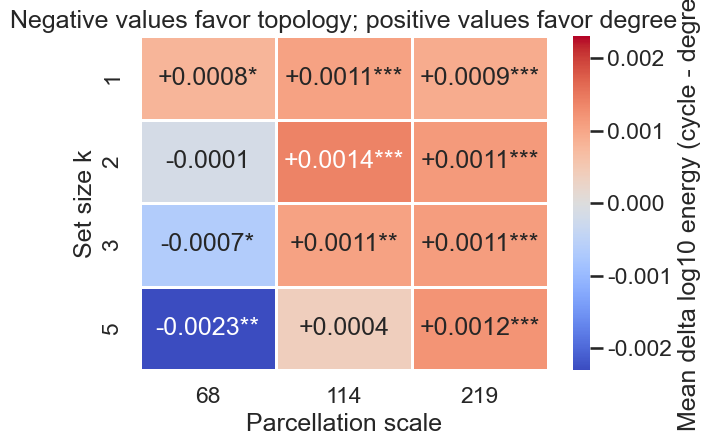

In [81]:
heatmap_values = per_k_tests.pivot(index='k', columns='scale', values='mean_cycle_minus_degree').sort_index()
heatmap_stars = per_k_tests.pivot(index='k', columns='scale', values='stars_holm').sort_index()
heatmap_ann = heatmap_values.copy().astype(str)
for k_value in heatmap_values.index:
    for scale_value in heatmap_values.columns:
        delta = heatmap_values.loc[k_value, scale_value]
        star = heatmap_stars.loc[k_value, scale_value]
        heatmap_ann.loc[k_value, scale_value] = f'{delta:+.4f}{star}'

fig, ax = plt.subplots(figsize=(6.8, 4.8))
limit = float(np.nanmax(np.abs(heatmap_values.to_numpy())))
sns.heatmap(
    heatmap_values,
    annot=heatmap_ann,
    fmt='',
    cmap='coolwarm',
    center=0.0,
    vmin=-limit,
    vmax=limit,
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Mean delta log10 energy (cycle - degree)'},
    ax=ax,
)
ax.set_xlabel('Parcellation scale')
ax.set_ylabel('Set size k')
ax.set_title('Negative values favor topology; positive values favor degree')
fig.tight_layout()
out = FIGURES_DIR / 'delta_cycle_minus_degree_heatmap_by_scale_and_k.svg'
fig.savefig(out, bbox_inches='tight')
out

## Figure: delta energy by scale for each set size

In [82]:
for k_value in sorted(per_k_summary['k'].unique()):
    subset = per_k_summary[per_k_summary['k'] == k_value].copy()
    fig, ax = plt.subplots(figsize=(6.6, 4.6))
    x = np.arange(len(subset))
    ax.bar(
        x,
        subset['mean_cycle_minus_degree'],
        yerr=subset['sem_cycle_minus_degree'],
        color=['#6a51a3', '#3182bd', '#31a354'],
        capsize=4,
        width=0.62,
    )
    ax.axhline(0.0, color='#444444', linewidth=1.0, linestyle='--')
    ax.set_xticks(x)
    ax.set_xticklabels([f"{int(scale)}" for scale in subset['scale']])
    ax.set_xlabel('Parcellation scale')
    ax.set_ylabel('Mean delta log10 energy\n(cycle - degree)')
    ax.set_title(f'k = {int(k_value)}')
    fig.tight_layout()
    out = FIGURES_DIR / f'delta_cycle_minus_degree_by_scale_k-{int(k_value)}.svg'
    fig.savefig(out, bbox_inches='tight')
    plt.close(fig)
    print(out)

/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/delta_cycle_minus_degree_by_scale_k-1.svg
/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/delta_cycle_minus_degree_by_scale_k-2.svg
/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/delta_cycle_minus_degree_by_scale_k-3.svg
/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/delta_cycle_minus_degree_by_scale_k-5.svg


## Figure: delta energy averaged over set size

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/delta_cycle_minus_degree_by_scale_avgk.svg')

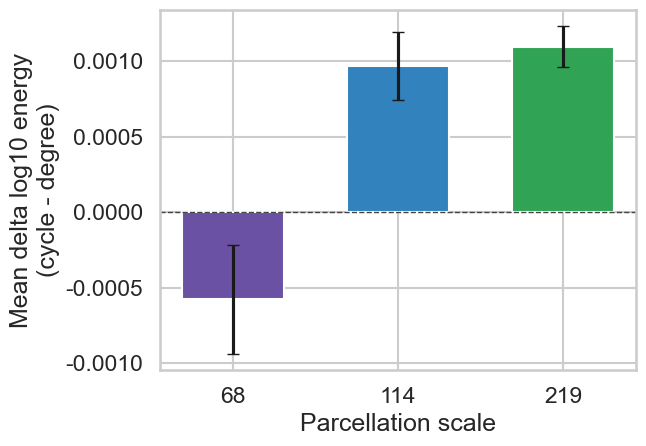

In [83]:
fig, ax = plt.subplots(figsize=(6.8, 4.8))
x = np.arange(len(energy_summary))
ax.bar(
    x,
    energy_summary['mean_cycle_minus_degree'],
    yerr=energy_summary['sem_cycle_minus_degree'],
    color=['#6a51a3', '#3182bd', '#31a354'],
    capsize=4,
    width=0.62,
)
ax.axhline(0.0, color='#444444', linewidth=1.0, linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels([f"{int(scale)}" for scale in energy_summary['scale']])
ax.set_xlabel('Parcellation scale')
ax.set_ylabel('Mean delta log10 energy\n(cycle - degree)')
fig.tight_layout()
out = FIGURES_DIR / 'delta_cycle_minus_degree_by_scale_avgk.svg'
fig.savefig(out, bbox_inches='tight')
out

## Global family correction used for manuscript claims

In [88]:
global_family = pd.concat([
    correlation_tests[['scale', 'p_value']].assign(test='rank_divergence_vs_relative_energy'),
    energy_summary[['scale', 'wilcoxon_p']].rename(columns={'wilcoxon_p': 'p_value'}).assign(test='static_energy_cycle_vs_degree'),
], ignore_index=True)
global_family['p_value_holm_global'] = holm_correction(global_family['p_value'].tolist())
global_family['reject_holm_global'] = global_family['p_value_holm_global'] < 0.05

correlation_tests = correlation_tests.merge(
    global_family[global_family['test'] == 'rank_divergence_vs_relative_energy'][['scale', 'p_value_holm_global', 'reject_holm_global']],
    on='scale', how='left'
)
energy_summary = energy_summary.merge(
    global_family[global_family['test'] == 'static_energy_cycle_vs_degree'][['scale', 'p_value_holm_global', 'reject_holm_global']],
    on='scale', how='left'
)

display(global_family.sort_values(['test', 'scale']))


,scale,p_value,test,p_value_holm_global,reject_holm_global
0,68,1.912624e-04,rank_divergence_vs_relative_energy,9.563120e-04,True
1,114,1.370010e-02,rank_divergence_vs_relative_energy,4.110029e-02,True
2,219,3.488938e-02,rank_divergence_vs_relative_energy,6.777359e-02,False
3,68,3.388679e-02,static_energy_cycle_vs_degree,6.777359e-02,False
4,114,2.193221e-04,static_energy_cycle_vs_degree,9.563120e-04,True
5,219,1.110060e-11,static_energy_cycle_vs_degree,6.660357e-11,True


## Figure: rank divergence versus relative control energy

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/rank_divergence_vs_relative_energy_by_scale.svg')

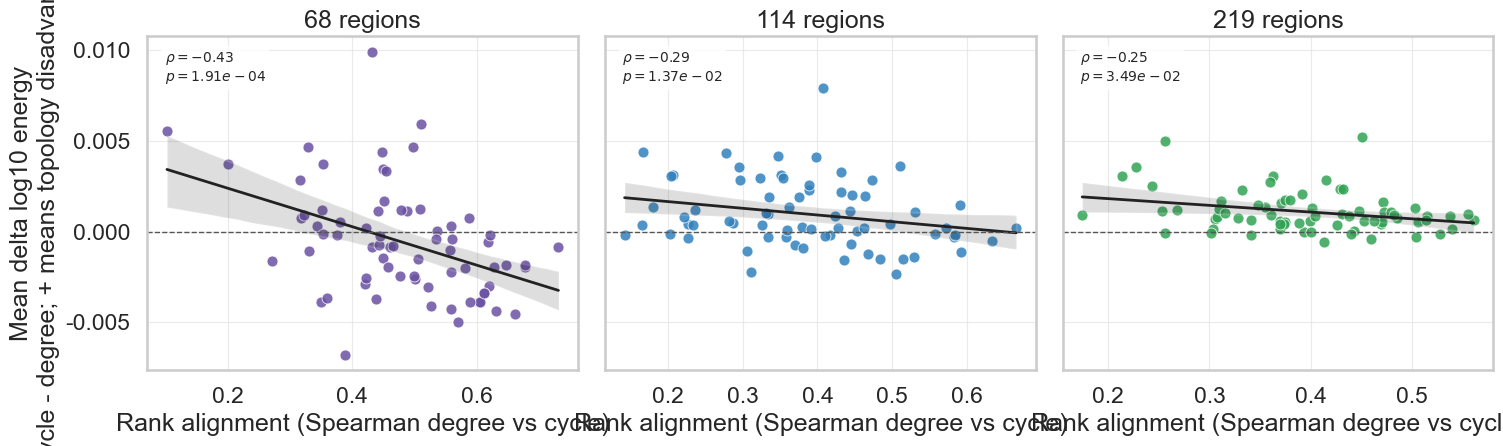

In [89]:
plot_df = rank_divergence.copy()
plot_df['scale_label'] = plot_df['scale'].map({68: '68 regions', 114: '114 regions', 219: '219 regions'})
plot_df['delta_energy_direction'] = np.where(plot_df['mean_delta_log10_energy'] > 0, 'Topology disadvantage', 'Topology advantage')
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8), sharey=True)
palette = {68: '#6a51a3', 114: '#3182bd', 219: '#31a354'}
for ax, scale in zip(axes, scales):
    subset = plot_df[plot_df['scale'] == scale].copy()
    sns.regplot(
        data=subset,
        x='spearman_degree_vs_topology',
        y='mean_delta_log10_energy',
        scatter_kws={'s': 62, 'alpha': 0.85, 'color': palette[scale], 'edgecolors': 'white', 'linewidths': 0.6},
        line_kws={'color': '#222222', 'linewidth': 2.0},
        ci=95,
        ax=ax,
    )
    rho, p_value = spearmanr(subset['spearman_degree_vs_topology'], subset['mean_delta_log10_energy'])
    ax.axhline(0.0, color='#555555', linewidth=1.0, linestyle='--')
    ax.set_title(f'{scale} regions')
    ax.set_xlabel('Rank alignment (Spearman degree vs cycle)')
    ax.grid(True, color='#dddddd', linewidth=0.8, alpha=0.6)
    ax.text(
        0.04,
        0.96,
        f'$\\rho = {rho:.2f}$\n$p = {p_value:.2e}$',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=10,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2.5),
    )
axes[0].set_ylabel('Mean delta log10 energy\n(cycle - degree; + means topology disadvantage)')
for ax in axes[1:]:
    ax.set_ylabel('')
fig.tight_layout()
out = FIGURES_DIR / 'rank_divergence_vs_relative_energy_by_scale.svg'
fig.savefig(out, bbox_inches='tight')
out

## Distribution of subject-level relative energy differences

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_rank_divergence_energy/rank_divergence_relative_energy_distribution.svg')

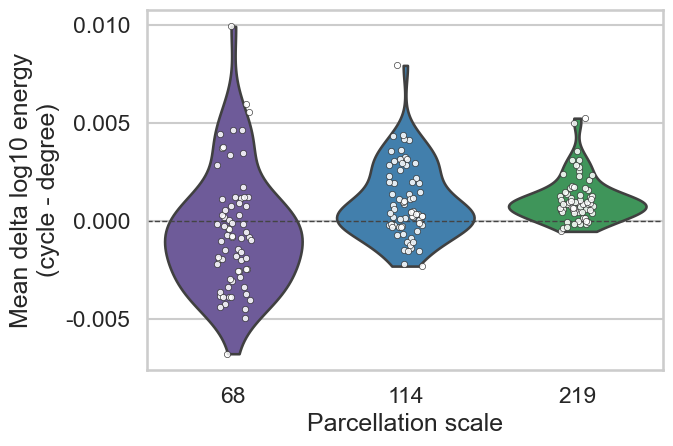

In [86]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
sns.violinplot(data=subject_mean, x='scale', y='cycle_minus_degree', hue='scale', inner=None, cut=0, palette=['#6a51a3', '#3182bd', '#31a354'], legend=False, ax=ax)
sns.stripplot(data=subject_mean, x='scale', y='cycle_minus_degree', color='white', edgecolor='#222222', linewidth=0.5, size=4.5, alpha=0.85, ax=ax)
ax.axhline(0.0, color='#444444', linewidth=1.0, linestyle='--')
ax.set_xlabel('Parcellation scale')
ax.set_ylabel('Mean delta log10 energy\n(cycle - degree)')
fig.tight_layout()
out = FIGURES_DIR / 'rank_divergence_relative_energy_distribution.svg'
fig.savefig(out, bbox_inches='tight')
out

## Manuscript-ready values

In [87]:
for _, row in section_summary.iterrows():
    corr_row = correlation_tests[correlation_tests['scale'] == row['scale']].iloc[0]
    print(
        f"Scale {int(row['scale'])}: mean rank alignment = {row['mean_rank_alignment']:.6f} +/- {row['sem_rank_alignment']:.6f}; "
        f"mean delta log10 energy = {row['mean_delta_log10_energy']:.6f} +/- {row['sem_delta_log10_energy']:.6f}; "
        f"rho = {row['rho_rank_vs_deltaE']:.6f}, p = {row['p_rank_vs_deltaE']:.6e}, global Holm p = {corr_row['p_value_holm_global']:.6e}"
    )
print('\nEnergy comparison summary')
for _, row in energy_summary.iterrows():
    print(
        f"Scale {int(row['scale'])}: cycle-degree mean = {row['mean_cycle_minus_degree']:.6f} +/- {row['sem_cycle_minus_degree']:.6f}; "
        f"cycle mean = {row['mean_cycle_energy']:.6f}; degree mean = {row['mean_degree_energy']:.6f}; "
        f"Wilcoxon p = {row['wilcoxon_p']:.6e}, global Holm p = {row['p_value_holm_global']:.6e}"
    )

Scale 68: mean rank alignment = 0.480505 +/- 0.014402; mean delta log10 energy = -0.000576 +/- 0.000359; rho = -0.431581, p = 1.912624e-04, global Holm p = 9.563120e-04
Scale 114: mean rank alignment = 0.386257 +/- 0.014625; mean delta log10 energy = 0.000969 +/- 0.000224; rho = -0.293395, p = 1.370010e-02, global Holm p = 4.110029e-02
Scale 219: mean rank alignment = 0.395427 +/- 0.010570; mean delta log10 energy = 0.001097 +/- 0.000135; rho = -0.252594, p = 3.488938e-02, global Holm p = 6.777359e-02

Energy comparison summary
Scale 68: cycle-degree mean = -0.000576 +/- 0.000359; cycle mean = 6.767585; degree mean = 6.768161; Wilcoxon p = 3.388679e-02, global Holm p = 6.777359e-02
Scale 114: cycle-degree mean = 0.000969 +/- 0.000224; cycle mean = 7.019389; degree mean = 7.018419; Wilcoxon p = 2.193221e-04, global Holm p = 9.563120e-04
Scale 219: cycle-degree mean = 0.001097 +/- 0.000135; cycle mean = 7.320842; degree mean = 7.319745; Wilcoxon p = 1.110060e-11, global Holm p = 6.660357